In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
from scipy.stats import mode



r_seed = 42

WORKDIR = 'C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_20076\2084090043.py:15: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch
c:\Users\cristiano.nascimento\git\LSTM_giroscopio_acelerometro\.venv\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [3]:
## get dataset
pd.set_option("display.precision", 9)

# select only sensor data from smart watches
data = pd.read_csv(WORKDIR+'/Code/DataPrep/kuhar_dataset_transformed.csv',dtype={"value": "float64"})

In [4]:
data.head()

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
0,0.0042305,-0.00028038,-0.0139060,-0.000042764,-0.00081629,-0.0029549,0.0
1,-0.0025436,0.02743300,0.0583000,-0.005450700,-0.00774770,-0.0096927,0.0
2,0.0516700,0.07185700,0.0806530,-0.012871000,-0.01569900,-0.0182940,0.0
3,0.0479170,0.02598000,-0.0045050,-0.020744000,-0.02114700,-0.0245410,0.0
4,-0.0069016,0.00143590,0.0054108,-0.023152000,-0.02181300,-0.0184710,0.0


In [5]:
data['Label'] = data['Label'].astype(int)

In [6]:
data.head()

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
0,0.0042305,-0.00028038,-0.0139060,-0.000042764,-0.00081629,-0.0029549,0
1,-0.0025436,0.02743300,0.0583000,-0.005450700,-0.00774770,-0.0096927,0
2,0.0516700,0.07185700,0.0806530,-0.012871000,-0.01569900,-0.0182940,0
3,0.0479170,0.02598000,-0.0045050,-0.020744000,-0.02114700,-0.0245410,0
4,-0.0069016,0.00143590,0.0054108,-0.023152000,-0.02181300,-0.0184710,0


In [7]:
data.isnull().sum()

Acc_X     0
Acc_Y     0
Acc_Z     0
Gyro_X    0
Gyro_Y    0
Gyro_Z    0
Label     0
dtype: int64

In [8]:
data.shape

(6225000, 7)

In [9]:
#remove the null class
data=data.dropna()

In [10]:
data.shape

(6225000, 7)

In [11]:
from scipy.signal import butter, filtfilt

# Define a function to apply a Butterworth low-pass filter
def low_pass_filter(data, cutoff, fs, order=4):
    """
    Applies a low-pass Butterworth filter to the given data.
    :param data: Array-like data to filter
    :param cutoff: Cutoff frequency for the filter
    :param fs: Sampling frequency of the data
    :param order: Order of the filter
    :return: Filtered data
    """
    nyquist = 0.5 * fs  # Nyquist frequency
    normal_cutoff = cutoff / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y

In [12]:
# Define parameters for the filter
cutoff_frequency = 5.0  # Adjust as necessary (Hz)
sampling_frequency = 50.0  # Sampling frequency (Hz)

# Apply the filter to the relevant columns
for column in ['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z']:
    data[column] = low_pass_filter(data[column], cutoff_frequency, sampling_frequency)

In [13]:
data["Label"].value_counts().sort_index()

Label
0     565800
1     562200
2     539100
3     559800
4     653400
5     543900
6     528600
7     399900
8     199800
9     144000
10    301500
11    264600
12     95100
13     77700
14    178500
15    239400
16    234300
17    137400
Name: count, dtype: int64

In [14]:
data.head()

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
0,0.004499185,-0.000013274,-0.013844791,-0.000083280,-0.000884246,-0.003028346,0
1,0.012373356,0.011406278,0.003581157,-0.006968738,-0.007622849,-0.009250840,0
2,0.018719676,0.020496026,0.017958755,-0.012998475,-0.013336152,-0.014443815,0
3,0.022655204,0.025894357,0.027410625,-0.017499410,-0.017279748,-0.017885228,0
4,0.024071233,0.027448406,0.031623843,-0.020141749,-0.019183197,-0.019355619,0


# **Data Exploration**

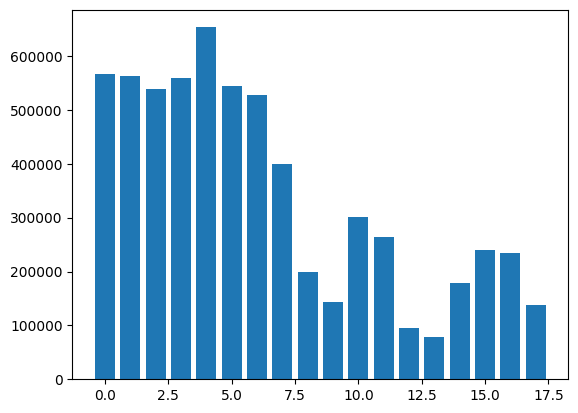

In [15]:
## the distribution of output classes
plt.bar(data["Label"].value_counts().index, data["Label"].value_counts().values)
plt.show()

In [16]:
#selecting only activities 0 to 3
data = data[data['Label'].isin([0,1,4,5,6])]

In [17]:
mapping_dict = {4:2,5:3,6:4}

In [18]:
data["Label"] = data["Label"].replace(to_replace=mapping_dict)

In [19]:
data.shape

(2853900, 7)

In [20]:
data["Label"].value_counts().sort_index()

Label
0    565800
1    562200
2    653400
3    543900
4    528600
Name: count, dtype: int64

# **Models**

In [21]:
import numpy as np

def category_count_categorical(labels_test_categorical):

    # Assuming your data is stored in a variable called `data`
    # Replace this with the actual data if it's available

    # Sum along the rows to get the count for each category
    category_counts_categorical = np.sum(labels_test_categorical, axis=0)

    # Print the counts
    print("Category counts:", category_counts_categorical)


In [22]:
import numpy as np

# Example array with binary class indications, replace this with your actual array
#array_data = np.random.randint(0, 2, (4027, 7)).astype(float)  # Example data; replace with your own

def count_active_classes(array_data):
    # Sum across each row to get the number of classes present in each row
    active_classes_per_row = np.sum(array_data, axis=1)
    
    # Count unique values in active_classes_per_row to get how many rows have each class count
    unique_counts, count_of_rows = np.unique(active_classes_per_row, return_counts=True)
    
    # Map each unique count of active classes to the number of rows with that count
    count_summary = dict(zip(unique_counts.astype(int), count_of_rows))
    
    return count_summary

# Get the count of active classes for each row
#active_classes_count = count_active_classes(array_data)

# Print the results
""" for active_class_count, row_count in active_classes_count.items():
    print(f"Number of rows with {active_class_count} active classes: {row_count}") """


' for active_class_count, row_count in active_classes_count.items():\n    print(f"Number of rows with {active_class_count} active classes: {row_count}") '

In [23]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [24]:
import numpy as np

def normalize_segments_to_mode(df_data_windowed, df_label_windowed):
    # Iterate through each window
    for i in range(df_label_windowed.shape[0]):
        # Get the current window
        window = df_label_windowed[i]
        
        # Replace -1 values with the first value of the window
        first_value = window[0]
        print(first_value)
        window = np.where(window == -1, first_value, window)
        
        # Update the window in the array
        df_label_windowed[i] = window
    
    return df_data_windowed, df_label_windowed


In [25]:
def apply_segmentation_no_sliding_window(df_data):
# Define window size and step size
    window_size = 300
    step_size = 30

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using  window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 200 segment has the value in label
         # Label consistency check    
        label_consistency = (
            df_data[['Label']][start_idx:end_idx].nunique()[0] == 1        
        ) 
        if label_consistency == True:
            segments[i] = df_data[['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z']][start_idx:end_idx]
            targets[i] = df_data[['Label']][start_idx:end_idx]
    return (segments,targets)

In [26]:
def apply_segmentation_with_sliding_window(df_data):
# Define window size and step size
    window_size = 300
    step_size = 30

    # Calculate number of windows
    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)
 
    # Create segmented data using  window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        
        # Check if window size matches expected
        if end_idx > df_data.shape[0]:
            break  # Avoid processing incomplete windows
        #populate the 3d array only if the 200 segment has the value in label
         # Label consistency check    
         
        label_consistency = (
            df_data[['Label']][start_idx:end_idx].nunique()[0] == 1        
        ) 
        if label_consistency == True:
            segments[i] = df_data[['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z']][start_idx:end_idx]
            targets[i] = df_data[['Label']][start_idx:end_idx]
    return (segments,targets)

In [27]:
import pandas as pd

def split_data_by_label(data, label_column, validation_ratio=0.2):
    """
    Splits a dataframe into validation and training sets based on a label column.
    
    Args:
        data (pd.DataFrame): The input dataframe.
        label_column (str): The name of the column containing labels.
        validation_ratio (float): The proportion of each label's data to include in the validation set.
    
    Returns:
        (pd.DataFrame, pd.DataFrame): A tuple containing the validation and training dataframes.
    """
    data_validation = pd.DataFrame()
    data_train = pd.DataFrame()
    
    # Iterate over each unique label and split data
    for label in data[label_column].unique():
        label_data = data[data[label_column] == label]  # Filter data for the current label
        split_index = int(len(label_data) * validation_ratio)  # Calculate split index
        data_validation = pd.concat([data_validation, label_data.iloc[:split_index]])  # Add first portion to validation
        data_train = pd.concat([data_train, label_data.iloc[split_index:]])  # Add remaining to train
    
    # Reset index for both dataframes
    data_validation = data_validation.reset_index(drop=True)
    data_train = data_train.reset_index(drop=True)
    
    return data_validation, data_train


In [28]:
from imblearn.over_sampling import SMOTE
from collections import Counter
import pandas as pd

def balance_data_with_smote(data, label_column):
    """
    Balances the class distribution in a DataFrame using SMOTE.

    Parameters:
        data (pd.DataFrame): The input DataFrame containing features and labels.
        label_column (str): The name of the column containing class labels.

    Returns:
        pd.DataFrame: A balanced DataFrame with the same structure as the input.
    """
    # Separate features and labels
    X = data.drop(columns=[label_column])
    y = data[label_column]

    # Check class distribution before SMOTE
    print("Before SMOTE:", Counter(y))

    # Apply SMOTE
    smote = SMOTE(sampling_strategy='auto', random_state=42)
    X_smote, y_smote = smote.fit_resample(X, y)

    # Check class distribution after SMOTE
    print("After SMOTE:", Counter(y_smote))

    # Combine features and labels back into a DataFrame
    balanced_data = pd.concat([pd.DataFrame(X_smote, columns=X.columns), 
                               pd.DataFrame(y_smote, columns=[label_column])], axis=1)

    return balanced_data

# Example usage:
# balanced_df = balance_data_with_smote(data, label_column='label')


In [29]:
data_validation, data_train = split_data_by_label(data,'Label')

In [30]:
data_validation.head()

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
0,0.004499185,-0.000013274,-0.013844791,-0.000083280,-0.000884246,-0.003028346,0
1,0.012373356,0.011406278,0.003581157,-0.006968738,-0.007622849,-0.009250840,0
2,0.018719676,0.020496026,0.017958755,-0.012998475,-0.013336152,-0.014443815,0
3,0.022655204,0.025894357,0.027410625,-0.017499410,-0.017279748,-0.017885228,0
4,0.024071233,0.027448406,0.031623843,-0.020141749,-0.019183197,-0.019355619,0


In [31]:
data_validation.shape

(570780, 7)

In [32]:
data_validation.Label.value_counts().sort_index()

Label
0    113160
1    112440
2    130680
3    108780
4    105720
Name: count, dtype: int64

In [33]:
data_train.head()

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
0,-0.007006505,-0.014424182,-0.008746889,0.008258143,0.008341958,0.008019816,0
1,-0.004847794,-0.015271762,-0.008882592,0.007376080,0.007281306,0.006901887,0
2,-0.005806693,-0.016698258,-0.011294877,0.006413785,0.006163035,0.005802983,0
3,-0.009339810,-0.017565841,-0.014457841,0.005504477,0.005150682,0.004893370,0
4,-0.014050758,-0.017010358,-0.016779499,0.004783791,0.004400791,0.004322530,0


In [34]:
data_train.tail()

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
2283115,0.355006717,0.442574546,0.513968906,-0.010010569,-0.013957712,-0.015467594,4
2283116,0.574447703,0.598263687,0.640068687,-0.035962492,-0.027997824,-0.024409421,4
2283117,0.648694859,0.563917405,0.538643378,-0.061261792,-0.034339667,-0.022961320,4
2283118,0.444315177,0.229266808,0.109558908,-0.073797555,-0.023416718,-0.003099525,4
2283119,-0.117024714,-0.444707777,-0.660475838,-0.061571962,0.011820778,0.039433998,4


In [35]:
data_train.shape

(2283120, 7)

In [36]:
data_train.Label.value_counts().sort_index()

Label
0    452640
1    449760
2    522720
3    435120
4    422880
Name: count, dtype: int64

In [37]:
X_validation_data, labels_val = apply_segmentation_no_sliding_window(data_validation)

In [38]:
X_train_data, labels_train = apply_segmentation_with_sliding_window(data_train)

In [39]:
X_train_data.shape

(76095, 300, 6)

In [40]:
segments_val,targets_val = X_validation_data, labels_val

In [41]:
segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
print(targets_val.shape)
print(segments_val.shape)

(1899, 300, 1)
(1899, 300, 6)


In [42]:
segments_train,targets_train = X_train_data, labels_train

In [43]:
segments_train,targets_train = delete_segments_not_fully_filled(segments_train,targets_train)
print(targets_train.shape)
print(segments_train.shape)

(7607, 300, 1)
(7607, 300, 6)


In [44]:
segments_train.shape

(7607, 300, 6)

In [45]:
labels_train.shape

(76095, 300, 1)

In [46]:
targets_val = targets_val.reshape(targets_val.shape[0],300)

In [47]:
print(targets_val.shape)

(1899, 300)


In [48]:
count_active_classes(targets_val)

{0: 377, 300: 374, 600: 435, 900: 362, 1200: 351}

In [49]:
print(targets_val)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [4 4 4 ... 4 4 4]
 [4 4 4 ... 4 4 4]
 [4 4 4 ... 4 4 4]]


In [50]:
labels_val = targets_val[:,0]

In [51]:
print(labels_val)

[0 0 0 ... 4 4 4]


In [52]:
print(labels_val.shape)

(1899,)


In [53]:
labels_val_categorical = to_categorical(labels_val,num_classes=5)

In [54]:
print(labels_val_categorical)

[[1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


In [55]:
print(labels_val_categorical.shape)

(1899, 5)


In [56]:
category_count_categorical(labels_val_categorical)

Category counts: [377. 374. 435. 362. 351.]


In [57]:
import numpy as np

def augment_data_crop(variable_data, label_data, crop_size=90):
    """
    Augments data using random cropping for windows with unique labels 3, 4, or 5.

    Args:
        variable_data (np.array): 3D array of variable data with shape (n, 300, 7).
        label_data (np.array): 2D array of label data with shape (n, 300, 1).
        crop_size (int): Size of the cropped window. Defaults to 90.

    Returns:
        tuple: Augmented variable data and label data as separate arrays.
    """
    def random_crop(window, crop_size=90):
        """
        Perform random cropping on a given window.
        Args:
            window (np.array): Input window with shape (100, 7).
            crop_size (int): Size of the cropped window.
        Returns:
            np.array: Cropped window with shape (100, 7).
        """
        start_idx = np.random.randint(0, window.shape[0] - crop_size + 1)
        return np.pad(window[start_idx:start_idx + crop_size], 
                      ((0, 300 - crop_size), (0, 0)), mode='constant')

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 14
            elif label == 4:
                synthetic_count = 16
            elif label == 5:
                synthetic_count = 20
            else:
                synthetic_count = 0
            
            # Generate synthetic windows
            for _ in range(synthetic_count):
                synthetic_window = random_crop(var_window, crop_size)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data

# Example usage:
# variable_data = np.random.rand(1000, 100, 7)  # Replace with actual data
# label_data = np.random.randint(0, 6, (3000, 100, 1))  # Replace with actual data
# augmented_var, augmented_labels = augment_data(variable_data, label_data)
# print("Augmented Variable Data Shape:", augmented_var.shape)
# print("Augmented Label Data Shape:", augmented_labels.shape)


In [58]:
import numpy as np
from scipy.interpolate import interp1d

def augment_data_with_time_warping(variable_data, label_data, warp_range=(0.95, 1.10)):
    """
    Augments data using Time Warping for windows with unique labels 3, 4, or 5.

    Args:
        variable_data (np.array): 3D array of variable data with shape (n, 100, 7).
        label_data (np.array): 2D array of label data with shape (n, 100, 1).
        warp_range (tuple): Range for time compression/stretching (default is ±5%-10%).

    Returns:
        tuple: Augmented variable data and label data as separate arrays.
    """

    def time_warp(window, warp_factor):
        """
        Apply time warping to a given window.
        Args:
            window (np.array): Input window with shape (100, 7).
            warp_factor (float): Factor to compress/stretch time.
        Returns:
            np.array: Time-warped window with shape (100, 7).
        """
        original_time = np.linspace(0, 1, window.shape[0])
        warped_time = np.linspace(0, 1, max(2, int(window.shape[0] * warp_factor)))  # Ensure at least 2 points

        # Interpolate each feature column separately
        interpolated_window = []
        for i in range(window.shape[1]):  # Iterate over each feature (axis=1)
            interpolator = interp1d(warped_time, 
                                    np.interp(warped_time, original_time, window[:, i]), 
                                    kind='linear', 
                                    fill_value="extrapolate", 
                                    bounds_error=False)
            interpolated_window.append(interpolator(original_time))

        return np.stack(interpolated_window, axis=1)



    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 28
            elif label == 4:
                synthetic_count = 34
            elif label == 5:
                synthetic_count = 30
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using Time Warping
            for _ in range(synthetic_count):
                warp_factor = np.random.uniform(*warp_range)
                synthetic_window = time_warp(var_window, warp_factor)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data

# Example usage:
# variable_data = np.random.rand(1000, 100, 7)  # Replace with actual data
# label_data = np.random.randint(0, 6, (1000, 100, 1))  # Replace with actual data
# augmented_var, augmented_labels = augment_data_with_time_warping(variable_data, label_data)
# print("Augmented Variable Data Shape:", augmented_var.shape)
# print("Augmented Label Data Shape:", augmented_labels.shape)


In [59]:
import numpy as np

def augment_data_with_magnitude_scaling(variable_data, label_data, scale_range=(0.9, 1.1)):
    """
    Augments data using magnitude scaling for windows with unique labels 3, 4, or 5.

    Args:
        variable_data (np.array): 3D array of variable data with shape (n, 100, 7).
        label_data (np.array): 2D array of label data with shape (n, 100, 1).
        scale_range (tuple): Range for scaling magnitude (default is ±10%).

    Returns:
        tuple: Augmented variable data and label data as separate arrays.
    """

    def magnitude_scaling(window, scale_factor):
        """
        Apply magnitude scaling to a given window.
        Args:
            window (np.array): Input window with shape (100, 7).
            scale_factor (float): Factor to scale magnitudes.
        Returns:
            np.array: Scaled window with shape (100, 7).
        """
        return window * scale_factor

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 10
            elif label == 4:
                synthetic_count = 10
            elif label == 5:
                synthetic_count = 20
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using magnitude scaling
            for _ in range(synthetic_count):
                scale_factor = np.random.uniform(*scale_range)
                synthetic_window = magnitude_scaling(var_window, scale_factor)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data


In [60]:
#print(occurrence_transitions_slide)

In [61]:
import numpy as np

def ocurrence_unique_values(targets_test):

    # Example of 3D array with the format (256, 200, 1)
    #data = np.random.randint(0, 3, (256, 250, 1))

    # Reshape to (256, 200) to simplify the processing
    data_reshaped = targets_test.reshape(targets_test.shape[0], 300)

    # Get unique values per window (each window has 200 rows)
    # Since the second dimension always contains the same value, we can just select the first column for each window
    unique_values = data_reshaped[:, 0]

    # Count occurrences of each unique value (0, 1, 2)
    unique, counts = np.unique(unique_values, return_counts=True)

    # Create a dictionary to show the counts of 0, 1, and 2
    occurrences = dict(zip(unique, counts))
    return occurrences


In [62]:
targets_train = targets_train.reshape(targets_train.shape[0],300)

In [63]:
print(targets_train.shape)

(7607, 300)


In [64]:
labels_train = targets_train[:,0]

In [65]:
labels_train_categorical = to_categorical(labels_train,num_classes=5)

In [66]:
print(labels_train_categorical)

[[1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


In [67]:
category_count_categorical(labels_train_categorical)

Category counts: [1508. 1499. 1742. 1449. 1409.]


In [68]:
X_train = segments_train
y_train = labels_train_categorical
X_validation = segments_val
y_validation = labels_val_categorical

In [69]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(7607, 300, 6)
(7607, 5)
(1899, 300, 6)
(1899, 5)


In [70]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [71]:
X_train,y_train = shuffle_data(X_train,y_train)
X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [72]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(7607, 300, 6)
(7607, 5)
(1899, 300, 6)
(1899, 5)


In [73]:
#from tensorflow.keras import regularizers

In [74]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

' def cria_LSTM(hp):\n  model = tf.keras.Sequential()  \n  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))\n  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation=\'relu\'))\n  model.add(tf.keras.layers.BatchNormalization())  \n  model.add(tf.keras.layers.Dense(units=4, activation=\'softmax\'))\n  model.compile(loss=\'categorical_crossentropy\', optimizer=tf.keras.optimizers.Adam(hp.Float(\n                    \'learning_rate\',\n                    min_value=1e-4,\n                    max_value=1e-2,\n                    sampling=\'LOG\',\n                    default=1e-3\n                )), metrics=[\'accuracy\'])\n  return model\n '

In [75]:
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(300, 6))
    
    # LSTM layer
    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), 
                    kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    return_sequences=True)(inputs)
    
    
    dense_out = Dense(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), activation='relu')(lstm_out)
    # Attention mechanism using Keras Attention layer
    attention = Attention()([dense_out, dense_out])
    
    # Context vector computation
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(5, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(hp.Float('learning_rate', 
                                                              min_value=1e-4, 
                                                              max_value=1e-2, 
                                                              sampling='LOG', 
                                                              default=1e-3)),
                  metrics=['accuracy'])
    
    return model


In [76]:
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K

def lstm_attention_sensor(hp):
    inputs = Input(shape=(200,6))
    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),return_sequences=True)(inputs)
    
    # Attention mechanism
    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation='relu')(lstm_out)    
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    
    output = Dense(6, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
    return model
 """

' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape\nimport keras.backend as K\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(200,6))\n    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n             recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),return_sequences=True)(inputs)\n    \n    # Attention mechanism\n    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation=\'relu\')(lstm_out)    \n    attention = Permute([2, 1])(attention)\n    attention = Activation(\'softmax\')(attention)\n    attention = Permute([2, 1])(attention)\n    \n    context_vector = Multiply()([lstm_out, attention])\n    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    \n    output

In [77]:
tuner = RandomSearch(
    lstm_attention_sensor,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [78]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [79]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=32, use_multiprocessing=True)

Trial 5 Complete [02h 36m 01s]
val_accuracy: 0.7756714224815369

Best val_accuracy So Far: 0.8709847331047058
Total elapsed time: 05h 33m 51s


In [80]:
tuner.results_summary()

Results summary
Results in C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro/Code/DataPrep/2024-11-21_17-13-28\lstm_acel_giro_multiclass
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 2 summary
Hyperparameters:
input_units_lstm1: 160
l2_reg1: 0.0013607174450468629
learning_rate: 0.0009887195863122636
Score: 0.8709847331047058

Trial 0 summary
Hyperparameters:
input_units_lstm1: 192
l2_reg1: 0.0011942731780421024
learning_rate: 0.0006562536901904111
Score: 0.8630858063697815

Trial 1 summary
Hyperparameters:
input_units_lstm1: 96
l2_reg1: 0.05977728042983696
learning_rate: 0.000505466655750672
Score: 0.784096896648407

Trial 4 summary
Hyperparameters:
input_units_lstm1: 256
l2_reg1: 0.0015159319577885927
learning_rate: 0.008547485565344062
Score: 0.7756714224815369

Trial 3 summary
Hyperparameters:
input_units_lstm1: 64
l2_reg1: 0.0905127409782462
learning_rate: 0.001715074355925934
Score: 0.7519747018814087


In [81]:
tuner.get_best_hyperparameters()[0].values

{'input_units_lstm1': 160,
 'l2_reg1': 0.0013607174450468629,
 'learning_rate': 0.0009887195863122636}

In [82]:
best_model = tuner.get_best_models(num_models=1)[0]

In [83]:
best_model.history

In [84]:
best_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 300, 6)]             0         []                            
                                                                                                  
 lstm (LSTM)                 (None, 300, 160)             106880    ['input_1[0][0]']             
                                                                                                  
 dense (Dense)               (None, 300, 160)             25760     ['lstm[0][0]']                
                                                                                                  
 attention (Attention)       (None, 300, 160)             0         ['dense[0][0]',               
                                                                     'dense[0][0]']           

In [85]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

60/60 [==============================] - 12s 184ms/step - loss: 0.4143 - accuracy: 0.8710


In [86]:
predictions = best_model.predict(X_validation)

60/60 [==============================] - 11s 181ms/step


In [87]:
print(y_validation)

[[1. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 ...
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0.]]


In [88]:
print(y_validation.shape)

(1899, 5)


In [89]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [90]:
print(y_validation_inverse)

[0 2 3 ... 1 2 2]


In [91]:
print(len(y_validation_inverse))

1899


In [92]:
print(predictions)

[[7.18709350e-01 1.24287575e-01 9.95458959e-06 1.56991333e-01
  1.82500128e-06]
 [5.70000085e-24 0.00000000e+00 1.00000000e+00 2.19524632e-35
  4.89996748e-17]
 [3.49080074e-05 1.61262124e-03 2.40780035e-04 9.98109818e-01
  1.91304457e-06]
 ...
 [4.63082403e-01 3.77433836e-01 7.68314112e-06 1.59474656e-01
  1.46624132e-06]
 [1.85857112e-20 4.95289843e-32 9.99007165e-01 4.46551758e-13
  9.92835849e-04]
 [1.58593287e-25 0.00000000e+00 1.00000000e+00 0.00000000e+00
  9.79984628e-17]]


In [93]:
classes_x=np.argmax(predictions,axis=1)

In [94]:
print(classes_x)

[0 2 3 ... 0 2 2]


In [95]:
print(len(classes_x))

1899


In [96]:
print(classes_x.shape)

(1899,)


In [97]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [98]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

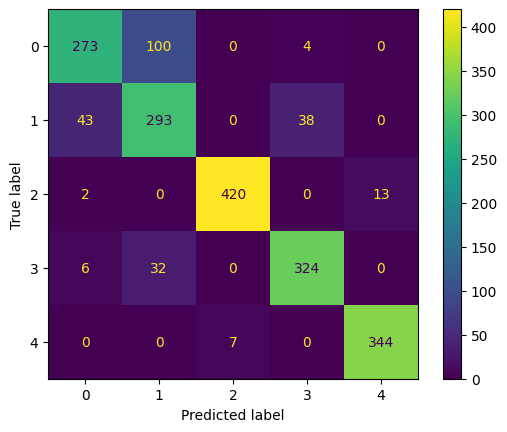

In [99]:
disp.plot()

In [100]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.84      0.72      0.78       377
           1       0.69      0.78      0.73       374
           2       0.98      0.97      0.97       435
           3       0.89      0.90      0.89       362
           4       0.96      0.98      0.97       351

    accuracy                           0.87      1899
   macro avg       0.87      0.87      0.87      1899
weighted avg       0.88      0.87      0.87      1899



In [ ]:
print(segments_test)

In [ ]:
print(labels_test_categorical.shape)

In [ ]:
print(labels_test_categorical)

In [ ]:
loss_test, accuracy_test = best_model.evaluate(segments_test, labels_test_categorical)

In [ ]:
predictions_test = best_model.predict(segments_test)

In [ ]:
print(predictions_test)

In [ ]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [ ]:
print(classes_x_test)

In [ ]:
labels_test_argmax = np.argmax(labels_test_categorical,axis=1)

In [ ]:
print(labels_test_argmax)

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

In [ ]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [ ]:
print(classification_report(labels_test_argmax, classes_x_test))

In [ ]:
best_model.save(WORKDIR+"/Model/best_models_saved_"+data_hora)